In [17]:
import kagglehub
import os

print("Downloading PaySim dataset...")

paysim_path = kagglehub.dataset_download("ealaxi/paysim1")

print(f"Path to dataset files: {paysim_path}")
print(f"Files in path: {os.listdir(paysim_path)}")


Using Colab cache for faster access to the 'paysim1' dataset.
Path to dataset files: /kaggle/input/paysim1
Files in path: ['PS_20174392719_1491204439457_log.csv']


In [18]:
import pandas as pd
import os


csv_files = [f for f in os.listdir(paysim_path) if f.endswith('.csv')]
file_path = os.path.join(paysim_path, csv_files[0])


df = pd.read_csv(file_path)
print(f"Dataset shape: {df.shape}")
df.head()


Dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [19]:
# Step 2: Initial Dataset Inspection
print("Dataset shape:", df.shape)
print("\nDataset Info:")
print(df.info())

print("\nMissing values check:")
print(df.isnull().sum())

fraud_counts = df['isFraud'].value_counts()
print("\nClass distribution (isFraud):")
print(fraud_counts)
print(f"Fraud transaction percentage: {(fraud_counts.get(1, 0) / len(df)) * 100:.4f}%")


Dataset shape: (6362620, 11)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB
None

Missing values check:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Class distribution (isFraud):
isFraud
0    6354407
1       8213
Name: count, dtype: int64
Fraud transaction percentage: 0.1291%


In [20]:
# Step 3: Feature Engineering and Data Cleaning
# Drop ID columns and rule-based heuristic column
df_clean = df.drop(columns=['nameOrig', 'nameDest', 'isFlaggedFraud'])

# One-hot encode the categorical transaction 'type'
df_clean = pd.get_dummies(df_clean, columns=['type'], drop_first=True, dtype=int)

# Engineering balance discrepancy features
df_clean['errorBalanceOrg'] = df_clean['newbalanceOrig'] + df_clean['amount'] - df_clean['oldbalanceOrg']
df_clean['errorBalanceDest'] = df_clean['oldbalanceDest'] + df_clean['amount'] - df_clean['newbalanceDest']

print("Cleaned dataset shape:", df_clean.shape)
df_clean.head()


Cleaned dataset shape: (6362620, 13)


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,errorBalanceOrg,errorBalanceDest
0,1,9839.64,170136.0,160296.36,0.0,0.0,0,0,0,1,0,0.0,9839.64
1,1,1864.28,21249.0,19384.72,0.0,0.0,0,0,0,1,0,0.0,1864.28
2,1,181.00,181.0,0.00,0.0,0.0,1,0,0,0,1,0.0,181.00
3,1,181.00,181.0,0.00,21182.0,0.0,1,1,0,0,0,0.0,21363.00
4,1,11668.14,41554.0,29885.86,0.0,0.0,0,0,0,1,0,0.0,11668.14


In [21]:
# Step 4: Time-based Chronological Train / Val / Test Split
# Sort by temporal step feature
df_clean = df_clean.sort_values('step').reset_index(drop=True)

FEATURE_COLS = [c for c in df_clean.columns if c != 'isFraud']
TARGET_COL = 'isFraud'

n = len(df_clean)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df_clean.iloc[:train_end]
val_df = df_clean.iloc[train_end:val_end]
test_df = df_clean.iloc[val_end:]

X_train_t = train_df[FEATURE_COLS]
y_train_t = train_df[TARGET_COL].values

X_val_t = val_df[FEATURE_COLS]
y_val_t = val_df[TARGET_COL].values

X_test_t = test_df[FEATURE_COLS]
y_test_t = test_df[TARGET_COL].values

print(f"Train split - Steps: {train_df['step'].min()} to {train_df['step'].max()} | Features shape: {X_train_t.shape} | Fraud count: {y_train_t.sum()}")
print(f"Val split   - Steps: {val_df['step'].min()} to {val_df['step'].max()} | Features shape: {X_val_t.shape} | Fraud count: {y_val_t.sum()}")
print(f"Test split  - Steps: {test_df['step'].min()} to {test_df['step'].max()} | Features shape: {X_test_t.shape} | Fraud count: {y_test_t.sum()}")


Train split - Steps: 1 to 323 | Features shape: (4453834, 12) | Fraud count: 3643
Val split   - Steps: 323 to 378 | Features shape: (954393, 12) | Fraud count: 562
Test split  - Steps: 378 to 743 | Features shape: (954393, 12) | Fraud count: 4008


In [22]:
# Step 5: Feature Scaling using StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit scaler exclusively on the training set to prevent data leakage
X_train_scaled = scaler.fit_transform(X_train_t)

# Transform validation and test sets
X_val_scaled = scaler.transform(X_val_t)
X_test_scaled = scaler.transform(X_test_t)

print("Scaling complete.")
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_val_scaled shape:   {X_val_scaled.shape}")
print(f"X_test_scaled shape:  {X_test_scaled.shape}")
print(f"Train mean (first feature): {X_train_scaled[:, 0].mean():.4f}")
print(f"Train std (first feature):  {X_train_scaled[:, 0].std():.4f}")


Scaling complete.
X_train_scaled shape: (4453834, 12)
X_val_scaled shape:   (954393, 12)
X_test_scaled shape:  (954393, 12)
Train mean (first feature): -0.0000
Train std (first feature):  1.0000


In [23]:
# Step 6: Define Comprehensive Evaluation Metrics Function
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    classification_report,
    confusion_matrix
)

def evaluate_predictions(y_true, y_prob, dataset_name="Validation"):
    # Calculate primary ranking metrics
    roc_auc = roc_auc_score(y_true, y_prob)
    pr_auc = average_precision_score(y_true, y_prob)

    # Determine best threshold based on F1-score optimization on PR curve
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
    best_f1 = f1_scores[best_idx]

    # Generate binary predictions with optimal threshold
    y_pred = (y_prob >= best_threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)

    print(f"=== Performance on {dataset_name} ===")
    print(f"ROC-AUC:          {roc_auc:.4f}")
    print(f"PR-AUC (Avg Prec): {pr_auc:.4f}")
    print(f"Optimal Threshold: {best_threshold:.4f}")
    print(f"Optimal F1-Score:  {best_f1:.4f}")
    print("\nConfusion Matrix:")
    print(cm)
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, digits=4))

    return {
        'roc_auc': roc_auc,
        'pr_auc': pr_auc,
        'best_threshold': best_threshold,
        'best_f1': best_f1,
        'confusion_matrix': cm
    }

print("Evaluation function ready.")


Evaluation function ready.


In [24]:
# Step 7: Train and Evaluate Baseline XGBoost Model
import xgboost as xgb

# Compute class imbalance ratio on training set
scale_pos_weight = (len(y_train_t) - sum(y_train_t)) / sum(y_train_t)
print(f"Computed scale_pos_weight: {scale_pos_weight:.2f}")

# Initialize XGBoost classifier with GPU-ready histogram method
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

# Fit model on training data
print("Training XGBoost baseline model...")
xgb_model.fit(X_train_t, y_train_t)

# Predict probabilities on validation set
y_val_xgb_prob = xgb_model.predict_proba(X_val_t)[:, 1]

# Evaluate performance on validation set
xgb_val_metrics = evaluate_predictions(y_val_t, y_val_xgb_prob, dataset_name="XGBoost - Validation Set")


Computed scale_pos_weight: 1221.57
Training XGBoost baseline model...
=== Performance on XGBoost - Validation Set ===
ROC-AUC:          1.0000
PR-AUC (Avg Prec): 0.9997
Optimal Threshold: 0.9179
Optimal F1-Score:  0.9982

Confusion Matrix:
[[953829      2]
 [     0    562]]

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    953831
           1     0.9965    1.0000    0.9982       562

    accuracy                         1.0000    954393
   macro avg     0.9982    1.0000    0.9991    954393
weighted avg     1.0000    1.0000    1.0000    954393



In [25]:
# Step 8: Evaluate XGBoost on Unseen Test Set
# Predict probabilities on test set
y_test_xgb_prob = xgb_model.predict_proba(X_test_t)[:, 1]

# Evaluate performance on test set using the optimal threshold found on validation set
print(f"Applying optimal validation threshold: {xgb_val_metrics['best_threshold']:.4f}")
xgb_test_metrics = evaluate_predictions(y_test_t, y_test_xgb_prob, dataset_name="XGBoost - Test Set")


Applying optimal validation threshold: 0.9179
=== Performance on XGBoost - Test Set ===
ROC-AUC:          1.0000
PR-AUC (Avg Prec): 0.9999
Optimal Threshold: 0.7357
Optimal F1-Score:  0.9994

Confusion Matrix:
[[950382      3]
 [     2   4006]]

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    950385
           1     0.9993    0.9995    0.9994      4008

    accuracy                         1.0000    954393
   macro avg     0.9996    0.9997    0.9997    954393
weighted avg     1.0000    1.0000    1.0000    954393



Top Feature Importances:
             feature  importance
3     newbalanceOrig    0.637584
10   errorBalanceOrg    0.325914
1             amount    0.014409
6      type_CASH_OUT    0.005691
2      oldbalanceOrg    0.004383
4     oldbalanceDest    0.003407
9      type_TRANSFER    0.002684
11  errorBalanceDest    0.002381
0               step    0.001711
5     newbalanceDest    0.001380
8       type_PAYMENT    0.000391
7         type_DEBIT    0.000065


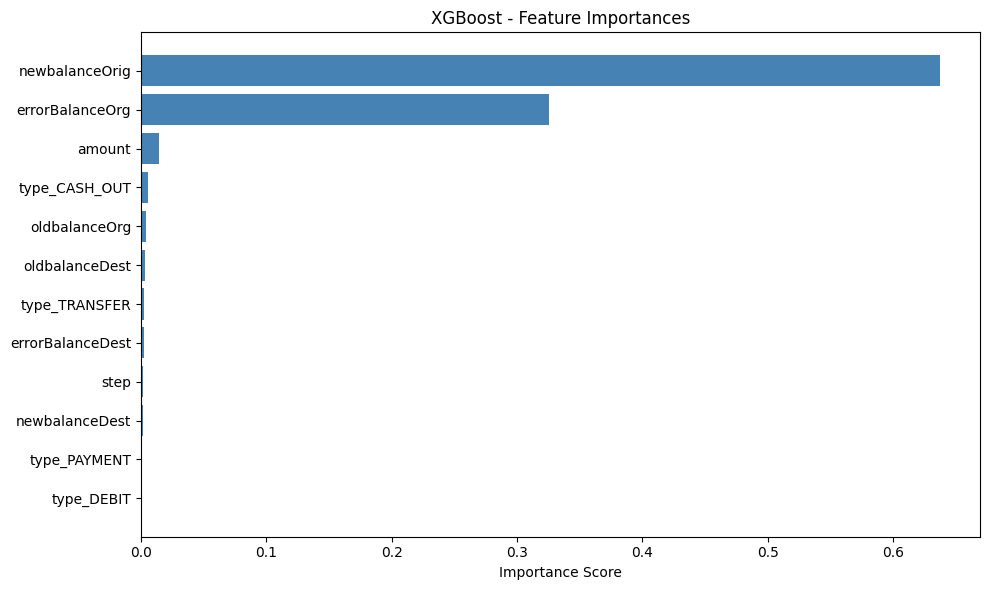

In [26]:
# Step 9: Feature Importance Analysis for XGBoost
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    'feature': FEATURE_COLS,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False)

print("Top Feature Importances:")
print(feature_importance)

# Plot feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importance['feature'][::-1], feature_importance['importance'][::-1], color='steelblue')
plt.xlabel('Importance Score')
plt.title('XGBoost - Feature Importances')
plt.tight_layout()
plt.show()


In [27]:
# Step 10: PyTorch Dataset, Architecture, and DataLoader Setup
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Set device (GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")

# Convert scaled numpy arrays to PyTorch float tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_t, dtype=torch.float32).unsqueeze(1)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_t, dtype=torch.float32).unsqueeze(1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_t, dtype=torch.float32).unsqueeze(1)

# Create optimized DataLoaders
BATCH_SIZE = 4096
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Define MLP architecture
class FraudMLP(nn.Module):
    def __init__(self, input_dim):
        super(FraudMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 16),
            nn.BatchNorm1d(16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)

input_dim = X_train_scaled.shape[1]
mlp_model = FraudMLP(input_dim=input_dim).to(device)
print(mlp_model)


Using compute device: cuda
FraudMLP(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [30]:
# Step 11: Train PyTorch MLP with Weighted Loss and Early Stopping
import torch.optim as optim

# Loss with positive class weight to balance fraud cases
pos_weight = torch.tensor([scale_pos_weight], dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = optim.Adam(mlp_model.parameters(), lr=0.001, weight_decay=1e-4)

EPOCHS = 20
best_val_pr_auc = 0.0
best_weights = None

print("Starting MLP training...")

for epoch in range(1, EPOCHS + 1):
    mlp_model.train()
    running_loss = 0.0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()
        outputs = mlp_model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_x.size(0)

    epoch_train_loss = running_loss / len(train_dataset)

    # Validation phase
    mlp_model.eval()
    val_preds = []
    with torch.no_grad():
        for batch_x, _ in val_loader:
            batch_x = batch_x.to(device)
            logits = mlp_model(batch_x)
            probs = torch.sigmoid(logits)
            val_preds.extend(probs.cpu().numpy().flatten())

    val_preds = np.array(val_preds)
    val_pr_auc = average_precision_score(y_val_t, val_preds)

    print(f"Epoch [{epoch}/{EPOCHS}] - Train Loss: {epoch_train_loss:.4f} | Val PR-AUC: {val_pr_auc:.4f}")

    if val_pr_auc > best_val_pr_auc:
        best_val_pr_auc = val_pr_auc
        best_weights = mlp_model.state_dict().copy()

# Restore best performing weights
if best_weights is not None:
    mlp_model.load_state_dict(best_weights)
    print(f"\nTraining finished. Best Val PR-AUC: {best_val_pr_auc:.4f}")


Starting MLP training...
Epoch [1/20] - Train Loss: 0.2812 | Val PR-AUC: 0.6330
Epoch [2/20] - Train Loss: 0.2633 | Val PR-AUC: 0.6731
Epoch [3/20] - Train Loss: 0.2517 | Val PR-AUC: 0.6506
Epoch [4/20] - Train Loss: 0.2424 | Val PR-AUC: 0.6818
Epoch [5/20] - Train Loss: 0.2373 | Val PR-AUC: 0.6843
Epoch [6/20] - Train Loss: 0.2292 | Val PR-AUC: 0.7075
Epoch [7/20] - Train Loss: 0.2167 | Val PR-AUC: 0.7131
Epoch [8/20] - Train Loss: 0.2141 | Val PR-AUC: 0.7050
Epoch [9/20] - Train Loss: 0.2038 | Val PR-AUC: 0.7380
Epoch [10/20] - Train Loss: 0.2072 | Val PR-AUC: 0.7070
Epoch [11/20] - Train Loss: 0.1963 | Val PR-AUC: 0.7146
Epoch [12/20] - Train Loss: 0.1968 | Val PR-AUC: 0.7183
Epoch [13/20] - Train Loss: 0.1928 | Val PR-AUC: 0.7683
Epoch [14/20] - Train Loss: 0.1897 | Val PR-AUC: 0.7449
Epoch [15/20] - Train Loss: 0.1892 | Val PR-AUC: 0.7498
Epoch [16/20] - Train Loss: 0.1819 | Val PR-AUC: 0.7436
Epoch [17/20] - Train Loss: 0.1873 | Val PR-AUC: 0.7896
Epoch [18/20] - Train Loss: 0.17

/tmp/ipykernel_1301/4282963596.py:24: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals_to_plot, X_test_scaled[:500], feature_names=feature_names)
/usr/local/lib/python3.13/dist-packages/shap/plots/_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(


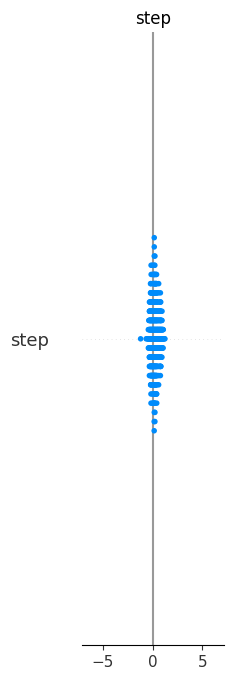

In [33]:
# Step 12: Explain MLP decisions using SHAP (GradientExplainer)
!pip install shap -q
import shap
import torch

# Feature names from the dataset
feature_names = FEATURE_COLS if 'FEATURE_COLS' in globals() else X_train_t.columns.tolist()

# Prepare background samples (100 random samples) and test samples (500 samples)
background = torch.tensor(X_train_scaled[:100], dtype=torch.float32).to(device)
test_subset = torch.tensor(X_test_scaled[:500], dtype=torch.float32).to(device)

mlp_model.eval()
explainer = shap.GradientExplainer(mlp_model, background)
shap_values = explainer.shap_values(test_subset)

# Handle output format for single-output binary classification
if isinstance(shap_values, list):
    shap_vals_to_plot = shap_values[0]
else:
    shap_vals_to_plot = shap_values

# Plot summary
shap.summary_plot(shap_vals_to_plot, X_test_scaled[:500], feature_names=feature_names)



In [36]:
import numpy as np
import pandas as pd

# Ensure shap_vals_to_plot is 2D: (samples, num_features)
shap_vals_2d = np.squeeze(np.array(shap_vals_to_plot))
if shap_vals_2d.ndim > 2:
    shap_vals_2d = shap_vals_2d.reshape(shap_vals_2d.shape[0], -1)

# Compute mean absolute SHAP value across all samples
mean_shap = np.abs(shap_vals_2d).mean(axis=0).ravel()

# Build ranking dataframe
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': mean_shap
}).sort_values(by='Importance', ascending=False)

print("=== Feature Importance Ranking for the MLP Model ===")
print(feature_importance.head(10).to_string(index=False))



=== Feature Importance Ranking for the MLP Model ===
         Feature  Importance
   type_CASH_OUT    1.332638
 errorBalanceOrg    0.631037
  newbalanceOrig    0.628211
   type_TRANSFER    0.609203
          amount    0.574803
errorBalanceDest    0.372225
            step    0.350816
   oldbalanceOrg    0.350723
    type_PAYMENT    0.310093
      type_DEBIT    0.307214


=== Fidelity (Faithfulness) Evaluation Results ===
Removed 'None (Baseline)   ' -> Resulting PR-AUC: 0.9862
Removed 'type_CASH_OUT     ' -> Resulting PR-AUC: 0.9041
Removed 'errorBalanceOrg   ' -> Resulting PR-AUC: 0.5652
Removed 'newbalanceOrig    ' -> Resulting PR-AUC: 0.5949
Removed 'type_TRANSFER     ' -> Resulting PR-AUC: 0.5013
Removed 'amount            ' -> Resulting PR-AUC: 0.1935
Removed 'errorBalanceDest  ' -> Resulting PR-AUC: 0.2483


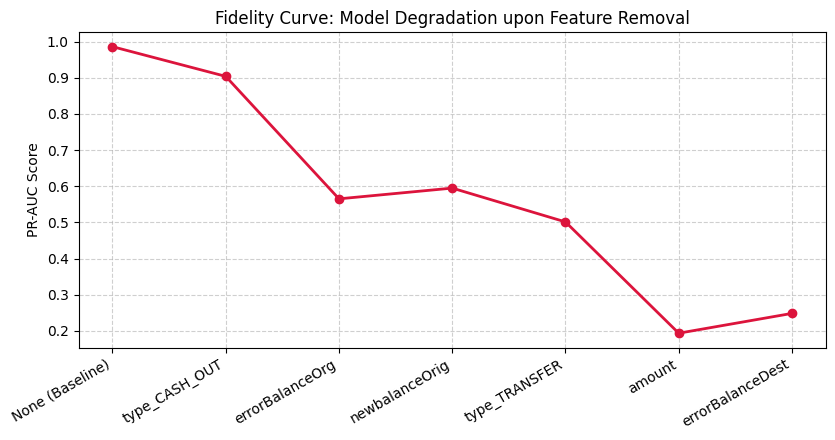

In [38]:
# Step 13: Fidelity Evaluation via Iterative Feature Removal (Fixed indexing)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

# Rank feature indices by SHAP importance (descending)
sorted_feature_indices = np.argsort(mean_shap)[::-1]

# Convert y_test_t to 1D numpy array safely
y_test_arr = np.asarray(y_test_t).ravel()

# Sample a test subset that includes both fraud and non-fraud transactions
fraud_indices = np.where(y_test_arr == 1)[0]
non_fraud_indices = np.where(y_test_arr == 0)[0]

# Take 500 fraud and 4500 non-fraud samples for a solid evaluation set (5000 total)
n_fraud = min(len(fraud_indices), 500)
n_non_fraud = min(len(non_fraud_indices), 4500)

eval_idx = np.concatenate([
    np.random.choice(fraud_indices, size=n_fraud, replace=False),
    np.random.choice(non_fraud_indices, size=n_non_fraud, replace=False)
])
np.random.shuffle(eval_idx)

X_eval_orig = X_test_scaled[eval_idx].copy()
y_eval = y_test_arr[eval_idx]

# Baseline evaluation without removing any features
mlp_model.eval()
with torch.no_grad():
    input_t = torch.tensor(X_eval_orig, dtype=torch.float32).to(device)
    baseline_preds = torch.sigmoid(mlp_model(input_t)).cpu().numpy().flatten()
baseline_prauc = average_precision_score(y_eval, baseline_preds)

prauc_scores = [baseline_prauc]
removed_features = ["None (Baseline)"]

# Iteratively mask top features with 0 (baseline value for standard scaled data)
X_perturbed = X_eval_orig.copy()
for idx in sorted_feature_indices[:6]:
    feat_name = feature_names[idx]
    removed_features.append(feat_name)

    # Mask this feature with zero
    X_perturbed[:, idx] = 0.0

    with torch.no_grad():
        perturbed_t = torch.tensor(X_perturbed, dtype=torch.float32).to(device)
        preds = torch.sigmoid(mlp_model(perturbed_t)).cpu().numpy().flatten()

    score = average_precision_score(y_eval, preds)
    prauc_scores.append(score)

# Print Fidelity Results
print("=== Fidelity (Faithfulness) Evaluation Results ===")
for feat, score in zip(removed_features, prauc_scores):
    print(f"Removed '{feat:<18}' -> Resulting PR-AUC: {score:.4f}")

# Plot Fidelity Curve
plt.figure(figsize=(8.5, 4.5))
plt.plot(range(len(prauc_scores)), prauc_scores, marker='o', color='crimson', linewidth=2)
plt.xticks(range(len(prauc_scores)), removed_features, rotation=30, ha='right')
plt.ylabel('PR-AUC Score')
plt.title('Fidelity Curve: Model Degradation upon Feature Removal')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("mlp_fidelity_curve.png", dpi=300)
plt.show()


In [39]:
# Step 14: Stability Evaluation under Input Perturbation (Robustness Metric)
import numpy as np
from scipy.stats import spearmanr
from sklearn.metrics.pairwise import cosine_similarity

# Select a subset of test samples for stability analysis (e.g., 100 samples)
test_stab_subset = X_test_scaled[:100].copy()
test_stab_tensor = torch.tensor(test_stab_subset, dtype=torch.float32).to(device)

# Step 1: Compute original SHAP explanations
mlp_model.eval()
orig_shap = explainer.shap_values(test_stab_tensor)
if isinstance(orig_shap, list):
    orig_shap = orig_shap[0]
orig_shap = np.squeeze(np.array(orig_shap))

# Step 2: Add slight Gaussian noise to the input (epsilon = 0.01 * std)
noise_level = 0.01
noise = np.random.normal(0, noise_level, size=test_stab_subset.shape)
noisy_subset = test_stab_subset + noise
noisy_tensor = torch.tensor(noisy_subset, dtype=torch.float32).to(device)

# Step 3: Compute SHAP explanations for noisy inputs
noisy_shap = explainer.shap_values(noisy_tensor)
if isinstance(noisy_shap, list):
    noisy_shap = noisy_shap[0]
noisy_shap = np.squeeze(np.array(noisy_shap))

# Step 4: Calculate stability metrics across all evaluated instances
cosine_sims = []
spearman_corrs = []

for i in range(len(test_stab_subset)):
    # Cosine Similarity between SHAP vectors
    cos_sim = cosine_similarity(orig_shap[i].reshape(1, -1), noisy_shap[i].reshape(1, -1))[0, 0]
    cosine_sims.append(cos_sim)

    # Spearman Rank Correlation of feature order
    corr, _ = spearmanr(orig_shap[i], noisy_shap[i])
    if not np.isnan(corr):
        spearman_corrs.append(corr)

mean_cosine_stability = np.mean(cosine_sims)
mean_spearman_stability = np.mean(spearman_corrs)

print("=== XAI Stability (Robustness) Evaluation Results ===")
print(f"Mean Cosine Similarity: {mean_cosine_stability:.4f} (Closer to 1.0 = More Robust)")
print(f"Mean Spearman Rank Correlation: {mean_spearman_stability:.4f} (Closer to 1.0 = More Stable Ranking)")


=== XAI Stability (Robustness) Evaluation Results ===
Mean Cosine Similarity: 0.9446 (Closer to 1.0 = More Robust)
Mean Spearman Rank Correlation: 0.8878 (Closer to 1.0 = More Stable Ranking)


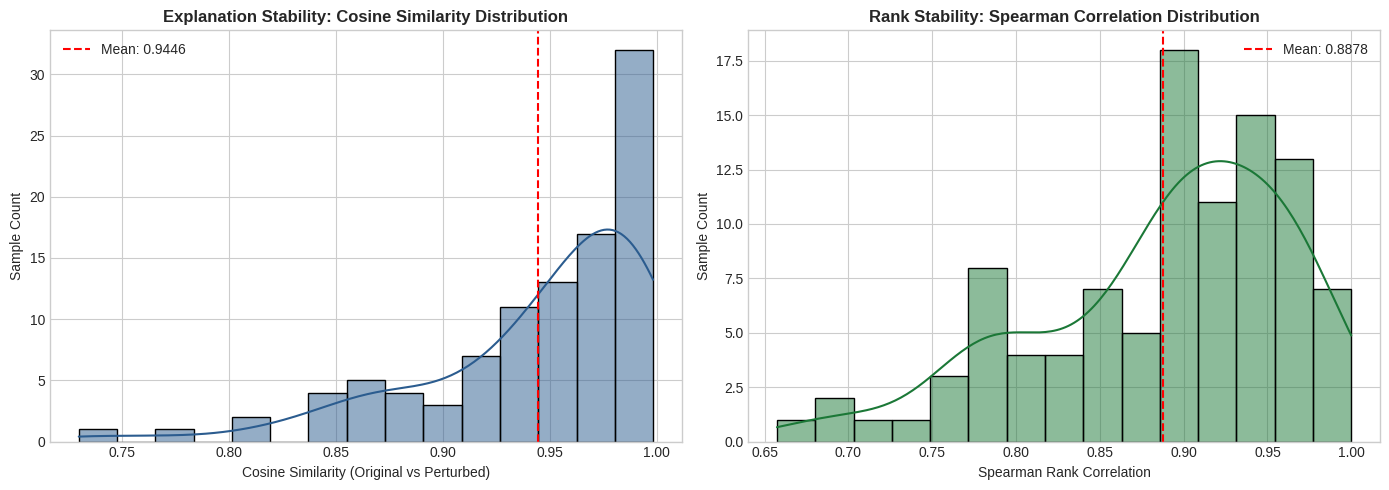

Stability evaluation plots saved as 'xai_stability_evaluation.png'.


In [40]:
# Step 15: Visualization of XAI Stability Metrics
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for publication-ready figures
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Cosine Similarity Distribution
sns.histplot(cosine_sims, kde=True, ax=axes[0], color='#2b5c8f', bins=15)
axes[0].axvline(mean_cosine_stability, color='red', linestyle='--', linewidth=1.5,
                label=f'Mean: {mean_cosine_stability:.4f}')
axes[0].set_title('Explanation Stability: Cosine Similarity Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Cosine Similarity (Original vs Perturbed)', fontsize=10)
axes[0].set_ylabel('Sample Count', fontsize=10)
axes[0].legend(fontsize=10)

# Plot 2: Spearman Rank Correlation Distribution
sns.histplot(spearman_corrs, kde=True, ax=axes[1], color='#1b7837', bins=15)
axes[1].axvline(mean_spearman_stability, color='red', linestyle='--', linewidth=1.5,
                label=f'Mean: {mean_spearman_stability:.4f}')
axes[1].set_title('Rank Stability: Spearman Correlation Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Spearman Rank Correlation', fontsize=10)
axes[1].set_ylabel('Sample Count', fontsize=10)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig("xai_stability_evaluation.png", dpi=300, bbox_inches='tight')
plt.show()

print("Stability evaluation plots saved as 'xai_stability_evaluation.png'.")
